In [7]:
%matplotlib inline
import numpy as np
import cv2
import copy
import matplotlib.image as mpimg
from matplotlib import pyplot as plt

Detected Circle Centroid = (692, 388), Radius = 201


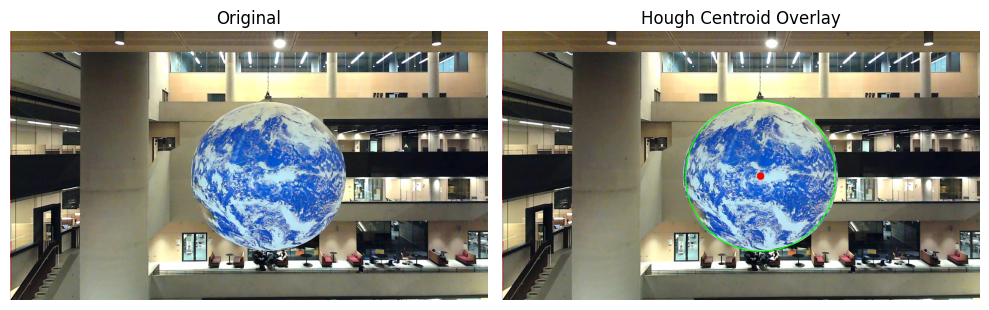

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread("image_2a.jpg")

img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Convert to grayscale
img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Blur the image 
img_blur = cv2.medianBlur(img_gray, 5)

# Hough Circle Transform
circles = cv2.HoughCircles(
    img_blur, 
    cv2.HOUGH_GRADIENT, 
    dp=1, 
    minDist=200, 
    param1=80, 
    param2=40, 
    minRadius=195, 
    maxRadius=210
)

cx, cy = 0, 0
radius = 0

# obtain the most prominent circle
if circles is not None:
    circles = np.uint16(np.around(circles))
    
    x, y, r = circles[0][0]
    
    cx, cy = int(x), int(y)
    radius = int(r)
    
    print(f"Detected Circle Centroid = ({cx}, {cy}), Radius = {radius}")
else:
    print("Warning: No circles detected by Hough Transform")

overlay = img_rgb.copy()

# draww the circle and outline the center point
if circles is not None:
    cv2.circle(overlay, (cx, cy), radius, (0, 255, 0), 2)
    cv2.circle(overlay, (cx, cy), 10, (255, 0, 0), -1)

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(img_rgb); ax[0].set_title("Original"); ax[0].axis("off")
ax[1].imshow(overlay); ax[1].set_title("Hough Centroid Overlay"); ax[1].axis("off")

plt.tight_layout()
plt.show()